# Lezione 2 — Onde termiche

Modulo *Radiazione termica e segnatura IR* (Master OQI, prof. R. Li Voti).

Una sorgente di calore modulata a frequenza \(f\) non manda un'onda nel senso
dell'ottica: manda un'**onda termica**. L'ampiezza decade in una lunghezza
di diffusione \(\mu\) e la fase ritarda di un radiante ogni \(\mu\).
È il regime in cui si misurano diffusività e spessori con la radiometria
fototermica.

Notebook precedente: `01_lezione_conduzione_diffusione.ipynb`.


## Le formule del regime periodico

Si scrive la temperatura come parte reale di \(\tilde T(z)\,e^{j\omega t}\).
L'equazione di diffusione, senza sorgenti distribuite, diventa

\[
\frac{d^2\tilde T}{dz^2}-\sigma^2\tilde T = 0,
\qquad
\sigma = \sqrt{\frac{j\omega}{D}} = \frac{1+j}{\mu},
\qquad
\mu = \sqrt{\frac{2D}{\omega}} = \sqrt{\frac{D}{\pi f}}.
\]

\(\mu\) è la **lunghezza di diffusione termica**: a profondità \(\mu\) l'ampiezza
è ridotta di un fattore \(e\) e la fase è ruotata di 1 rad.

Una sorgente piana in superficie, di flusso \(I_0 e^{j\omega t}\), lancia nel
semi-spazio \(z>0\)

\[
\tilde T(z) = \frac{I_0}{e\sqrt{j\omega}}\,e^{-\sigma z},
\qquad e=\sqrt{k\rho c}.
\]

Due conseguenze immediate, entrambe usate in laboratorio:

- in superficie la temperatura è in ritardo di \(45^\circ\) sul flusso;
- l'ampiezza in superficie scala come \(f^{-1/2}\).


## 0. Setup


In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (8.4, 4.7),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.35,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 11,
    "axes.unicode_minus": False,
})
np.set_printoptions(precision=4, suppress=True)
print("Ambiente pronto.")


Ambiente pronto.


In [2]:
def diffusivita(k, rho, c):
    return k / (rho * c)

def effusivita(k, rho, c):
    return np.sqrt(k * rho * c)

def mu_therm(D, f):
    """Lunghezza di diffusione termica μ = sqrt(D / (π f))."""
    return np.sqrt(D / (np.pi * f))

# Stessi ordini di grandezza della lezione 1.
MAT = {
    "Rame": (401.0, 8960.0, 385.0),
    "Acciaio": (15.0, 7800.0, 500.0),
    "Bronzo": (50.0, 8700.0, 380.0),
    "Vetro": (1.0, 2500.0, 750.0),
    "Aria": (0.026, 1.16, 1007.0),
    "Suolo": (1.2, 1500.0, 800.0),   # D = 1,0·10⁻⁶ m²/s, ordine di grandezza di un suolo
}
D = {n: diffusivita(*p) for n, p in MAT.items()}
E = {n: effusivita(*p) for n, p in MAT.items()}
print(f"Suolo: D = {D['Suolo']:.2e} m²/s")


Suolo: D = 1.00e-06 m²/s


## 1. Quanto penetra l'onda

A 1 Hz un metallo è «trasparente» per qualche millimetro; un vetro o un suolo
si chiudono in una frazione di millimetro. Alzare la frequenza accorcia \(\mu\)
come \(f^{-1/2}\): è il modo con cui si sceglie la profondità sondabile.


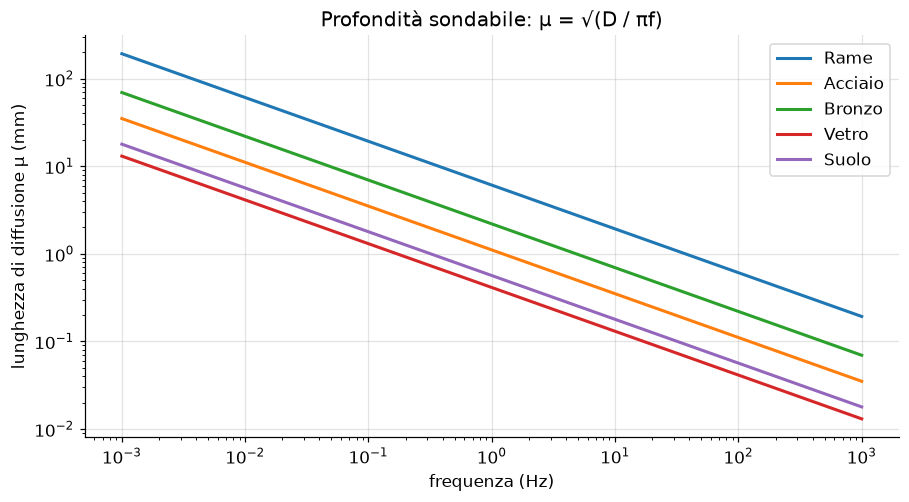

materiale      μ a 1 Hz    μ a 10 Hz   μ a 100 Hz
Rame             6.08 mm       1.92 mm       0.61 mm
Acciaio          1.11 mm       0.35 mm       0.11 mm
Bronzo           2.19 mm       0.69 mm       0.22 mm
Vetro            0.41 mm       0.13 mm       0.04 mm
Aria             2.66 mm       0.84 mm       0.27 mm
Suolo            0.56 mm       0.18 mm       0.06 mm


In [3]:
f = np.geomspace(1e-3, 1e3, 400)
fig, ax = plt.subplots()
for nome in ["Rame", "Acciaio", "Bronzo", "Vetro", "Suolo"]:
    ax.loglog(f, mu_therm(D[nome], f) * 1e3, lw=2, label=nome)
ax.set_xlabel("frequenza (Hz)")
ax.set_ylabel("lunghezza di diffusione μ (mm)")
ax.set_title("Profondità sondabile: μ = √(D / πf)")
ax.legend()
fig.tight_layout()
plt.show()

print(f"{'materiale':10} {'μ a 1 Hz':>12} {'μ a 10 Hz':>12} {'μ a 100 Hz':>12}")
for nome in ["Rame", "Acciaio", "Bronzo", "Vetro", "Aria", "Suolo"]:
    vals = [mu_therm(D[nome], freq) * 1e3 for freq in (1, 10, 100)]
    print(f"{nome:10} {vals[0]:10.2f} mm {vals[1]:10.2f} mm {vals[2]:10.2f} mm")

# Controllo analitico: a z = μ l'ampiezza è 1/e.
mu = mu_therm(D["Acciaio"], 10.0)
sigma = (1 + 1j) / mu
assert np.isclose(np.exp(-sigma.real * mu), 1 / np.e)
assert np.isclose(sigma.imag * mu, 1.0)


## 2. Fotografia dell'onda

A un istante fissato il profilo è una cosinusoide smorzata,

\[
T(z,t)=T_0\,e^{-z/\mu}\cos(\omega t - z/\mu - \pi/4).
\]

Il \(-\pi/4\) è il ritardo di superficie rispetto al flusso. Andando in
profondità la cresta si sposta e si abbassa: non è un fronte che viaggia
a velocità costante, perché \(\mu\) stesso dipende dalla frequenza.


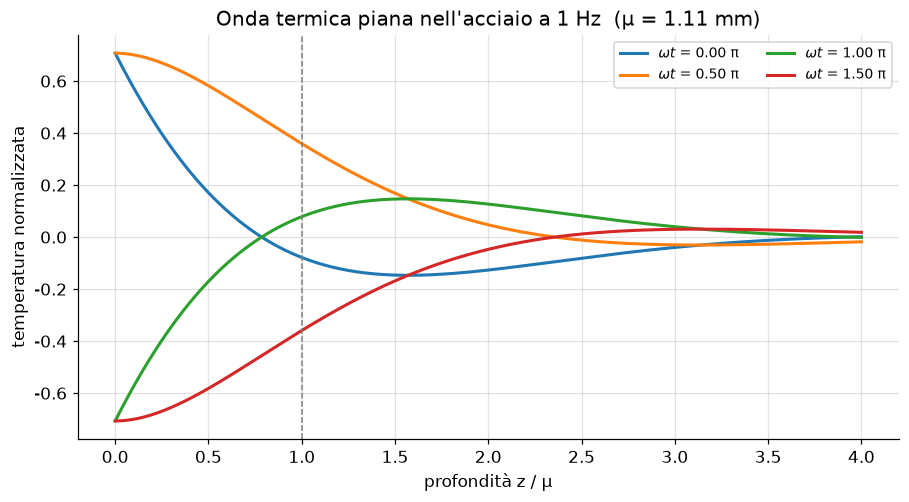

Ritardo della temperatura superficiale sul flusso: -45.0°


In [4]:
f0 = 1.0
mu = mu_therm(D["Acciaio"], f0)
z = np.linspace(0.0, 4 * mu, 500)
omega = 2 * np.pi * f0

fig, ax = plt.subplots()
for fase in (0.0, np.pi / 2, np.pi, 3 * np.pi / 2):
    # fase = ωt. Il flusso è proporzionale a cos(ωt); la temperatura ha −π/4.
    T = np.exp(-z / mu) * np.cos(fase - z / mu - np.pi / 4)
    ax.plot(z / mu, T, lw=2, label=fr"$\omega t$ = {fase/np.pi:.2f} π")
ax.axvline(1.0, color="0.5", ls="--", lw=1)
ax.set_xlabel("profondità z / μ")
ax.set_ylabel("temperatura normalizzata")
ax.set_title(f"Onda termica piana nell'acciaio a {f0:.0f} Hz  (μ = {mu*1e3:.2f} mm)")
ax.legend(ncol=2, fontsize=9)
fig.tight_layout()
plt.show()

# Ritardo di superficie: arg(1/sqrt(j)) = −π/4.
ritardo = np.angle(1 / np.sqrt(1j))
print(f"Ritardo della temperatura superficiale sul flusso: {np.degrees(ritardo):.1f}°")
assert np.isclose(ritardo, -np.pi / 4)


## 3. Ampiezza e fase contro la profondità

In un grafico semilogaritmico l'ampiezza è una retta. La fase, in radianti,
è una retta con la **stessa** pendenza se la profondità è misurata in unità
di \(\mu\): ampiezza \(e^{-z/\mu}\), fase \(-z/\mu\).

Dalla pendenza sperimentale della fase contro \(\sqrt{f}\) si ricava \(D\).
È il principio della misura di diffusività in radiometria fototermica
(campioni tipo AISI nella lezione).


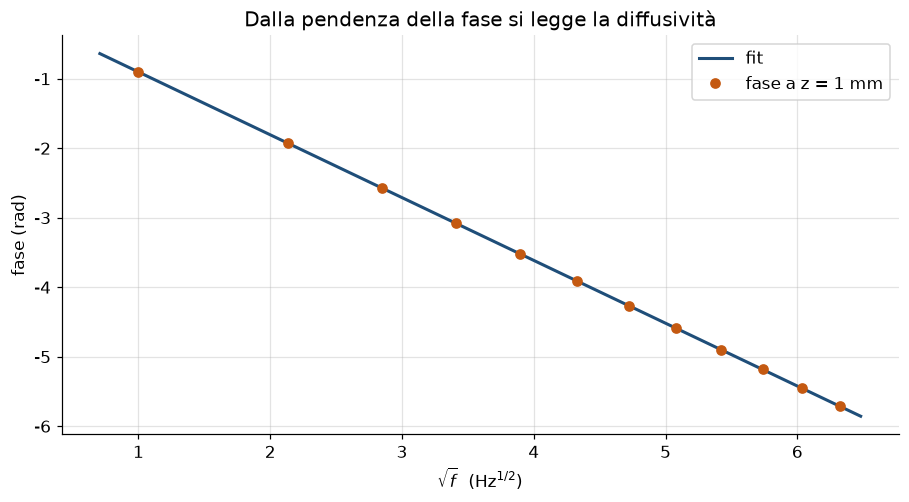

D vera  = 3.846e-06 m²/s
D dal fit di fase = 3.846e-06 m²/s


In [5]:
f_mis = np.linspace(1.0, 40.0, 12)
z_mis = 1.0e-3   # termocoppia, o la profondità efficace del segnale, a 1 mm
D_vero = D["Acciaio"]
fase = -z_mis * np.sqrt(np.pi * f_mis / D_vero)

# Fit lineare fase = a + b √f.  b = −z √(π/D)  →  D = π z² / b².
sqrt_f = np.sqrt(f_mis)
b, a = np.polyfit(sqrt_f, fase, 1)
D_fit = np.pi * z_mis**2 / b**2

fig, ax = plt.subplots()
f_fit = np.linspace(0.5, 42, 200)
ax.plot(np.sqrt(f_fit), a + b * np.sqrt(f_fit), color="#1f4e79", lw=2, label="fit")
ax.plot(sqrt_f, fase, "o", color="#c45911", label="fase a z = 1 mm")
ax.set_xlabel(r"$\sqrt{f}$  (Hz$^{1/2}$)")
ax.set_ylabel("fase (rad)")
ax.set_title("Dalla pendenza della fase si legge la diffusività")
ax.legend()
fig.tight_layout()
plt.show()

print(f"D vera  = {D_vero:.3e} m²/s")
print(f"D dal fit di fase = {D_fit:.3e} m²/s")
assert np.isclose(D_fit, D_vero, rtol=1e-6)


## 4. Il termometro del suolo: giorno e anno

È l'esempio della lezione sulle oscillazioni di temperatura in profondità.
Con \(D \approx 10^{-6}\,\mathrm{m^2/s}\) (ordine di grandezza di un suolo) la
lunghezza di diffusione di un'oscillazione di periodo \(P\) è

\[
\mu = \sqrt{\frac{D P}{\pi}}.
\]

Il giorno e l'anno differiscono di un fattore \(\sqrt{365}\approx 19\):
l'onda diurna si spegne nel primo metro, quella annuale arriva a qualche metro.
Il profilo disegnato qui è il fenomeno mostrato a lezione, calcolato con una
diffusività tipica: non è il fit della curva sperimentale di Roma.


μ giornaliera = 16.6 cm
μ annuale     = 3.17 m
rapporto      = 19.1   (√365 ≈ 19.1)


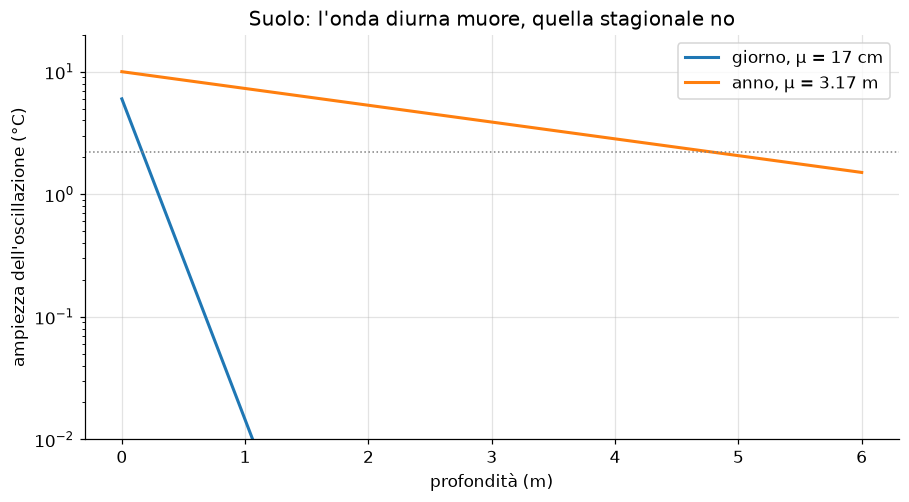

Oscillazione diurna ridotta all'1% a z = 76 cm.
Alla stessa profondità l'onda annuale vale ancora 79% .


In [6]:
D_suolo = D["Suolo"]
giorno = 86400.0
anno = 365.25 * giorno
mu_g = mu_therm(D_suolo, 1 / giorno)
mu_a = mu_therm(D_suolo, 1 / anno)
print(f"μ giornaliera = {mu_g*100:.1f} cm")
print(f"μ annuale     = {mu_a:.2f} m")
print(f"rapporto      = {mu_a/mu_g:.1f}   (√365 ≈ {np.sqrt(365.25):.1f})")

z = np.linspace(0.0, 6.0, 400)
A_g, A_a = 6.0, 10.0   # ampiezze in superficie, °C, valori didattici

fig, ax = plt.subplots()
ax.semilogy(z, A_g * np.exp(-z / mu_g), lw=2, label=f"giorno, μ = {mu_g*100:.0f} cm")
ax.semilogy(z, A_a * np.exp(-z / mu_a), lw=2, label=f"anno, μ = {mu_a:.2f} m")
ax.axhline(A_g / np.e, color="0.5", ls=":", lw=1)
ax.set_xlabel("profondità (m)")
ax.set_ylabel("ampiezza dell'oscillazione (°C)")
ax.set_title("Suolo: l'onda diurna muore, quella stagionale no")
ax.set_ylim(1e-2, 20)
ax.legend()
fig.tight_layout()
plt.show()

# A che profondità l'oscillazione diurna vale l'1% di quella in superficie?
z_1 = -np.log(0.01) * mu_g
print(f"Oscillazione diurna ridotta all'1% a z = {z_1*100:.0f} cm.")
print(f"Alla stessa profondità l'onda annuale vale ancora {np.exp(-z_1/mu_a)*100:.0f}% .")


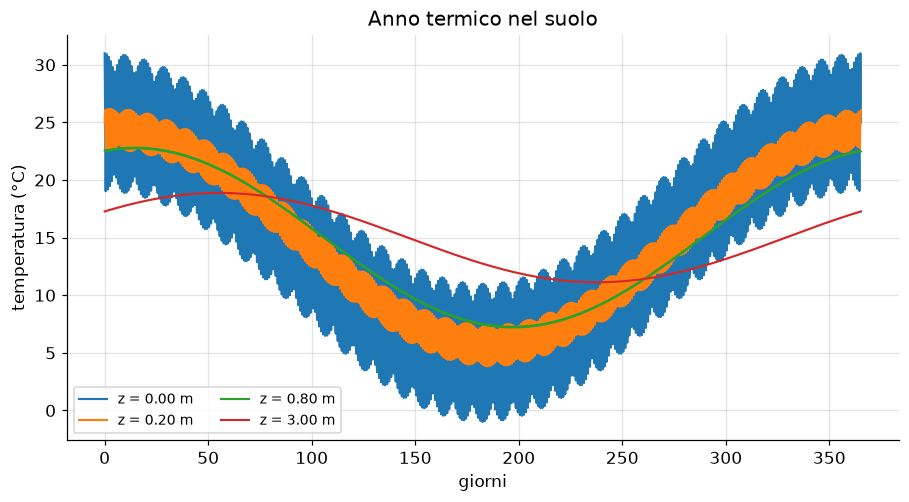

A 3 m il massimo stagionale arriva 55 giorni dopo la superficie.


In [7]:
# Un anno di temperatura a quattro profondità. t = 0 è un massimo estivo superficiale.
t = np.linspace(0.0, anno, 1500)
T_media = 15.0
omega_g = 2 * np.pi / giorno
omega_a = 2 * np.pi / anno
profondita = [0.0, 0.20, 0.80, 3.0]

fig, ax = plt.subplots()
for z0 in profondita:
    T = (T_media
         + A_a * np.exp(-z0 / mu_a) * np.cos(omega_a * t - z0 / mu_a)
         + A_g * np.exp(-z0 / mu_g) * np.cos(omega_g * t - z0 / mu_g))
    ax.plot(t / giorno, T, lw=1.4, label=f"z = {z0:.2f} m")
ax.set_xlabel("giorni")
ax.set_ylabel("temperatura (°C)")
ax.set_title("Anno termico nel suolo")
ax.legend(ncol=2, fontsize=9)
fig.tight_layout()
plt.show()

# Ritardo dell'onda annuale, in giorni, a 3 m.
ritardo_giorni = (3.0 / mu_a) / (2 * np.pi) * 365.25
print(f"A 3 m il massimo stagionale arriva {ritardo_giorni:.0f} giorni dopo la superficie.")


## In sintesi

- In regime periodico \(\sigma=(1+j)/\mu\) con \(\mu=\sqrt{D/(\pi f)}\). Ampiezza e fase portano la stessa informazione.
- La superficie risponde con \(45^\circ\) di ritardo e con ampiezza \(\propto f^{-1/2}\).
- La pendenza della fase contro \(\sqrt{f}\) misura \(D\) senza termocoppie distribuite in profondità: basta conoscere \(z\).
- Nel suolo, \(\mu_\mathrm{anno}/\mu_\mathrm{giorno}\approx 19\). A meno di un metro il ciclo diurno è già sparito; a qualche metro resta solo la stagione, in ritardo di mesi.
